In [1]:
import pandas as pd

In [2]:
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
caminho = "https://www-usr.inf.ufsm.br/~joaquim/UFSM/DM/ds/AgeOfMythology_work.csv"
df = pd.read_csv(caminho, dtype="string", keep_default_na=False, encoding="utf-8")

In [3]:
df

,Unit,Age,Cost,Pop,DmgHack,DmgPierce,DmgCrush,Range,HP,ArmorHack,ArmorPierce,ArmorCrush,Speed,LOS,Train time,Bonus,Other,Class
0,Pegasus,1,50F 2Fv,2,--,--,--,0,140,50,50,99,5,18,6,,,Myth Unit
1,Centaur,2,200W 15Fv,3,--,12,--,12,220,25,35,80,5,20,19,"Myth units, -Heroes",,Myth Unit
2,Cyclops,2,250F 22Fv,4,15,--,12,2,600,40,50,80,3.2,16,20,Myth units,,Myth Unit
3,Minotaur,2,200F 16Fv,4,15,--,10,2,300,60,50,80,4,20,20,Myth units,,Myth Unit
4,Hydra,3,250F 28Fv,5,20,--,10,3,800,60,40,80,4,16,20,"Myth units, -Heroes",,Myth Unit
5,Manticore,3,300W 28Fv,5,--,11**,--,16,420,30,60,80,4.3,20,17,"Myth units, -Heroes",,Myth Unit
6,Nemean Lion,3,200G 25Fv,4,20,--,10,1,660,30,60,80,4.8,16,20,"Myth units, -Heroes",,Myth Unit
7,Colossus,4,300G 40Fv,5,20,--,50,3,1100_,50,80,80,2.4,16,24,"Myth units, -Heroes",,Myth Unit
8,Chimera,4,300G 30Fv,4,20,--,--,1,800,60,60,80,5.3,16,20,"Myth units, -Heroes",,Myth Unit
9,Medusa,4,250G 40Fv,5,--,15,12.5,10,360,60,70,80,4.3,18,20,"Myth units, -Heroes",,Myth Unit


Limpeza dos dados

In [4]:

import pandas as pd

RECURSOS = {
    "F": "cost_food",
    "W": "cost_wood",
    "G": "cost_gold",
    "Fv": "cost_favor",
}

COLUNAS_NUMERICAS = [
    "age", "pop", "dmg_hack", "dmg_pierce", "dmg_crush",
    "range", "hp", "armor_hack", "armor_pierce",
    "armor_crush", "speed", "los", "train_time",
]


def extrair_custos(valor):
    if pd.isna(valor) or valor in ("", "--"):
        return {nome: 0 for nome in RECURSOS.values()}

    custos = {nome: 0 for nome in RECURSOS.values()}

    for item in valor.replace(",", " ").split():
        recurso = next(
            (r for r in RECURSOS if item.endswith(r)),
            None
        )

        if recurso is None:
            raise ValueError(f"Custo inválido: {item}")

        quantidade = item.removesuffix(recurso)

        if not quantidade.isdigit():
            raise ValueError(f"Custo inválido: {item}")

        custos[RECURSOS[recurso]] += int(quantidade)

    return custos


def limpar_dataset(df) -> pd.DataFrame:
    df = df.copy()

    # Padroniza espaços e valores ausentes
    df.columns = [
        " ".join(col.replace("\u00a0", " ").split())
        for col in df.columns
    ]

    for coluna in df.columns:
        df[coluna] = df[coluna].map(
            lambda x: " ".join(x.replace("\u00a0", " ").split())
            if isinstance(x, str) else x
        )
    
    df = df.replace("", pd.NA)

    # Renomeia colunas
    df = df.rename(columns={
        "Unit": "unit",
        "Age": "age",
        "Cost": "cost_raw",
        "Pop": "pop",
        "DmgHack": "dmg_hack",
        "DmgPierce": "dmg_pierce",
        "DmgCrush": "dmg_crush",
        "Range": "range",
        "HP": "hp",
        "ArmorHack": "armor_hack",
        "ArmorPierce": "armor_pierce",
        "ArmorCrush": "armor_crush",
        "Speed": "speed",
        "LOS": "los",
        "Train time": "train_time",
        "Bonus": "bonus",
        "Other": "other",
        "Class": "unit_class",
    })

    # Corrige erros de escrita
    for coluna in ["unit_class", "bonus"]:
        df[coluna] = df[coluna].str.replace(
            "Infantary", "Infantry", regex=False
        )

    # Extrai custos
    custos = df["cost_raw"].apply(extrair_custos)
    custos = pd.DataFrame(custos.tolist(), index=df.index)

    for coluna in custos.columns:
        df[coluna] = custos[coluna].astype("Int64")

    # Remove marcações dos danos
    for coluna in ["dmg_hack", "dmg_pierce", "dmg_crush"]:
        df[coluna] = df[coluna].str.replace("*", "", regex=False)

    # Corrige HP
    df["hp"] = df["hp"].str.removesuffix("_")

    # Remove símbolo de porcentagem das armaduras
    for coluna in ["armor_hack", "armor_pierce", "armor_crush"]:
        df[coluna] = df[coluna].str.removesuffix("%")

    colunas_dmg = ["dmg_hack", "dmg_pierce", "dmg_crush"]

    df["does_attack"] = df[colunas_dmg].ne("--").any(axis=1).astype(int)


    # Converte colunas numéricas
    for coluna in COLUNAS_NUMERICAS:

        substituicoes = {
            "--": 0 if coluna.startswith("dmg_") else pd.NA,
            "none": pd.NA,
        }

        df[coluna] = pd.to_numeric(
            df[coluna].replace(substituicoes),
            errors="raise"
        )

    # Define tipos
    colunas_inteiras = [
        "age", "pop", "range", "hp",
        "armor_hack", "armor_pierce", "armor_crush",
        "los", "train_time",
    ]

    colunas_decimais = [
        "dmg_hack", "dmg_pierce", "dmg_crush", "speed",
    ]

    df[colunas_inteiras] = df[colunas_inteiras].astype("Int64")
    df[colunas_decimais] = df[colunas_decimais].astype("Float64")

    # Remove duplicatas
    df = df.drop_duplicates().reset_index(drop=True)

    # Valida valores
    for coluna in ["armor_hack", "armor_pierce", "armor_crush"]:
        if (df[coluna].dropna() > 100).any():
            raise ValueError(f"Armadura inválida: {coluna}")

    # Organiza colunas
    ordem = [
        "unit", "unit_class", "age",
        "cost_food", "cost_wood", "cost_gold", "cost_favor",
        "pop", "hp",
        "dmg_hack", "dmg_pierce", "dmg_crush",
        "armor_hack", "armor_pierce", "armor_crush",
        "range", "speed", "los", "train_time",
        "bonus", "other", "does_attack",
    ]

    return df[ordem]


In [5]:
df_limpo = limpar_dataset(df)

In [6]:
display(df_limpo)

,unit,unit_class,age,cost_food,cost_wood,cost_gold,cost_favor,pop,hp,dmg_hack,dmg_pierce,dmg_crush,armor_hack,armor_pierce,armor_crush,range,speed,los,train_time,bonus,other,does_attack
0,Pegasus,Myth Unit,1,50,0,0,2,2,140,0.0,0.0,0.0,50,50,99,0,5.0,18,6,NaN,NaN,0
1,Centaur,Myth Unit,2,0,200,0,15,3,220,0.0,12.0,0.0,25,35,80,12,5.0,20,19,"Myth units, -Heroes",NaN,1
2,Cyclops,Myth Unit,2,250,0,0,22,4,600,15.0,0.0,12.0,40,50,80,2,3.2,16,20,Myth units,NaN,1
3,Minotaur,Myth Unit,2,200,0,0,16,4,300,15.0,0.0,10.0,60,50,80,2,4.0,20,20,Myth units,NaN,1
4,Hydra,Myth Unit,3,250,0,0,28,5,800,20.0,0.0,10.0,60,40,80,3,4.0,16,20,"Myth units, -Heroes",NaN,1
5,Manticore,Myth Unit,3,0,300,0,28,5,420,0.0,11.0,0.0,30,60,80,16,4.3,20,17,"Myth units, -Heroes",NaN,1
6,Nemean Lion,Myth Unit,3,0,0,200,25,4,660,20.0,0.0,10.0,30,60,80,1,4.8,16,20,"Myth units, -Heroes",NaN,1
7,Colossus,Myth Unit,4,0,0,300,40,5,1100,20.0,0.0,50.0,50,80,80,3,2.4,16,24,"Myth units, -Heroes",NaN,1
8,Chimera,Myth Unit,4,0,0,300,30,4,800,20.0,0.0,0.0,60,60,80,1,5.3,16,20,"Myth units, -Heroes",NaN,1
9,Medusa,Myth Unit,4,0,0,250,40,5,360,0.0,15.0,12.5,60,70,80,10,4.3,18,20,"Myth units, -Heroes",NaN,1


Descobrir quantos dados tem de cada classe e quais coluna tem valor ausente

In [7]:
print(df_limpo.isna().sum()[lambda s: s > 0])   #colunas com valores ausentes
df_limpo["unit_class"].value_counts()

age            2
pop            1
range          1
train_time     3
bonus         17
other         73
dtype: int64


unit_class
Myth Unit          30
Hero               18
Animal              7
Siege               6
Cavalry             6
Melee Infantry      5
Ship                5
Ranged Infantry     4
Spear Infantry      1
Ranged Cavalry      1
Name: count, dtype: int64

Carregar o conjunto sem classe e escolher atributos.
Padronizar os dados de teste e treino e ajustar o valores ausentes para treino 

In [8]:
caminho_noClass = "https://www-usr.inf.ufsm.br/~joaquim/UFSM/DM/ds/AgeOfMythology_noClass.csv"
teste = pd.read_csv(caminho_noClass, encoding="utf-8-sig")

In [9]:
teste

,Age,Pop,DmgHack,DmgPierce,DmgCrush,Range,HP,ArmorHack,ArmorPierce,ArmorCrush,Speed,Train time,Favor
0,3,5,12,0,0,1,800,60,60,80,3.60,19,15
1,2,1,5,0,0,1,50,10,5,99,3.00,20,5
2,2,3,11,5,0,1,400,30,50,99,3.80,17,5
3,3,2,0,6,0,20,60,15,15,99,3.75,12,0
4,3,3,8,0,0,1,120,10,35,99,4.00,15,0
5,3,2,8,4,0,1,95,15,10,99,3.50,14,0
6,4,3,10,0,30,16,180,30,70,50,2.50,21,0
7,4,3,11,10,0,1,140,15,40,99,3.50,22,0
8,2,3,10,0,8,1,175,50,25,80,4.00,26,10
9,4,5,20,0,0,1,360,60,69,80,4.10,30,25


In [10]:
# padronizar 
mapa = {
    "Age": "age", "Pop": "pop",
    "DmgHack": "dmg_hack", "DmgPierce": "dmg_pierce", "DmgCrush": "dmg_crush",
    "Range": "range", "HP": "hp",
    "ArmorHack": "armor_hack", "ArmorPierce": "armor_pierce", "ArmorCrush": "armor_crush",
    "Speed": "speed", "Train time": "train_time", "Favor": "cost_favor",
}
teste = teste.rename(columns=mapa)

BASE = list(mapa.values())              #as 13 colunas que existem nos dois arquivos
ATRIBUTOS = BASE + ["does_attack"]      # 13 + does attack

#deixar apenas os atributo que tem no sem classe
treino = df_limpo[["unit_class"] + BASE].copy()
treino[BASE] = treino[BASE].fillna(0).astype(float) #tratar na
treino["does_attack"] = (treino[["dmg_hack", "dmg_pierce", "dmg_crush"]].sum(axis=1) > 0).astype(int)

teste = teste[BASE].astype(float)
teste["does_attack"] = (teste[["dmg_hack", "dmg_pierce", "dmg_crush"]].sum(axis=1) > 0).astype(int)

treino.head()


,unit_class,age,pop,dmg_hack,dmg_pierce,dmg_crush,range,hp,armor_hack,armor_pierce,armor_crush,speed,train_time,cost_favor,does_attack
0,Myth Unit,1.0,2.0,0.0,0.0,0.0,0.0,140.0,50.0,50.0,99.0,5.0,6.0,2.0,0
1,Myth Unit,2.0,3.0,0.0,12.0,0.0,12.0,220.0,25.0,35.0,80.0,5.0,19.0,15.0,1
2,Myth Unit,2.0,4.0,15.0,0.0,12.0,2.0,600.0,40.0,50.0,80.0,3.2,20.0,22.0,1
3,Myth Unit,2.0,4.0,15.0,0.0,10.0,2.0,300.0,60.0,50.0,80.0,4.0,20.0,16.0,1
4,Myth Unit,3.0,5.0,20.0,0.0,10.0,3.0,800.0,60.0,40.0,80.0,4.0,20.0,28.0,1


In [11]:

X = treino[ATRIBUTOS]     # perguntas
y = treino["unit_class"]  # resposta

Teste de  diferença entre os dados, faz a média do valores de cada atributo por classe

In [12]:
treino.groupby("unit_class")[["age", "pop", "dmg_hack", "dmg_pierce", "dmg_crush", "range", "hp",
       "armor_hack", "armor_pierce", "armor_crush", "speed", "train_time",
       "cost_favor"]].mean().round(1)

,age,pop,dmg_hack,dmg_pierce,dmg_crush,range,hp,armor_hack,armor_pierce,armor_crush,speed,train_time,cost_favor
unit_class,,,,,,,,,,,,,
Animal,2.7,2.1,8.7,0.0,0.0,0.9,77.1,25.0,20.7,99.0,4.2,20.1,8.1
Cavalry,3.0,2.7,9.2,0.0,0.0,1.0,193.3,21.7,37.5,99.0,5.0,11.8,0.0
Hero,2.1,2.4,9.7,2.6,0.3,5.8,302.0,25.8,31.1,94.6,4.5,15.4,2.4
Melee Infantry,2.2,1.6,8.0,0.0,0.0,1.0,92.0,35.0,23.0,99.0,4.5,8.6,0.0
Myth Unit,2.9,4.1,11.8,5.6,8.4,5.5,519.3,44.8,53.2,80.6,4.3,17.6,22.9
Ranged Cavalry,3.0,3.0,0.0,8.5,0.0,20.0,90.0,30.0,20.0,99.0,5.0,6.0,0.0
Ranged Infantry,2.8,2.2,1.1,3.5,1.5,16.2,65.0,18.8,16.2,99.0,4.0,13.2,0.0
Ship,2.2,2.0,4.0,1.2,1.2,6.4,262.0,32.0,44.0,21.0,5.6,15.2,0.0
Siege,3.5,3.3,0.0,5.3,28.7,18.2,245.8,15.8,91.8,81.7,2.7,20.0,0.0


Métricas de avaliação

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import (train_test_split, KFold, RepeatedKFold,
                                     cross_validate, cross_val_predict)
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import (accuracy_score, precision_score, make_scorer,
                             classification_report, ConfusionMatrixDisplay)

# métricas para a acuraácia padrao
def resumo_metricas(y_real, y_prev):
    return {
        "acurácia": accuracy_score(y_real, y_prev),
        "precisão (macro)": precision_score(y_real, y_prev, average="macro", zero_division=0),
        "precisão (ponderada)": precision_score(y_real, y_prev, average="weighted", zero_division=0),
    }

# métricas para a validação cruzada (uma nota por fold)
METRICAS_CV = {
    "acuracia": "accuracy",
    "precisao": make_scorer(precision_score, average="macro", zero_division=0),
}
kf = KFold(n_splits=10, shuffle=True, random_state=42)

def avaliar_cv(modelo, dados=None, cv=kf):
    """Validação cruzada com acurácia E precisão; devolve média e desvio dos folds."""
    dados = X if dados is None else dados
    r = cross_validate(modelo, dados, y, cv=cv, scoring=METRICAS_CV)
    return {
        "acurácia": r["test_acuracia"].mean(),
        "desvio acurácia": r["test_acuracia"].std(),
        "precisão (macro)": r["test_precisao"].mean(),
        "desvio precisão": r["test_precisao"].std(),
    }

Separar o dataset e criar a árvore. \
Divide o dataset em 80% / 30%

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

In [ ]:
RARAS_NO_TREINO = True   #False = divisão simples, sem estratificar

# Devolve:  atributos de treino, atributos de teste,
# classes de treino, classes de teste.
if RARAS_NO_TREINO:
    raras = y.map(y.value_counts()) < 2          # classes com apenas 1 exemplo
    X_train, X_test, y_train, y_test = train_test_split(
        X[~raras], y[~raras], test_size=0.3, random_state=42, stratify=y[~raras])
    X_train = pd.concat([X_train, X[raras]])     # as raras vão sempre para o treino
    y_train = pd.concat([y_train, y[raras]])
else:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(len(X_train), len(X_test))

58 25


In [16]:
arvore = DecisionTreeClassifier(criterion="entropy", random_state=42).fit(X_train, y_train)
print("Profundidade:", arvore.get_depth(), "-  Folhas:", arvore.get_n_leaves())


Profundidade: 6 -  Folhas: 15


DecisionTreeClassifier implementa o CART

visualizar a árvore e as regras

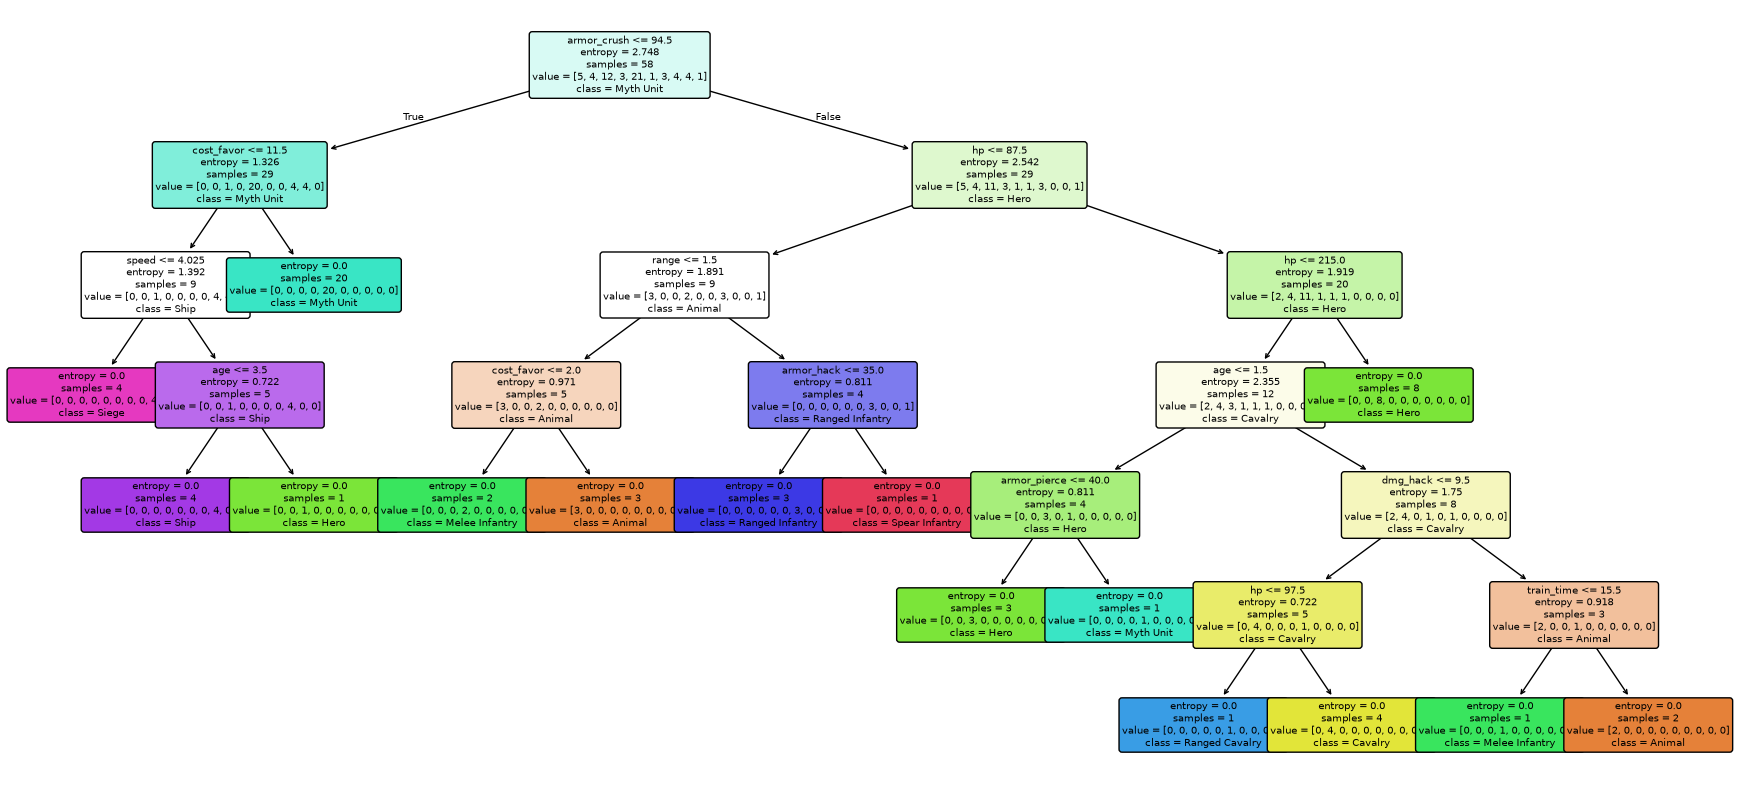

In [17]:
fig, ax = plt.subplots(figsize=(22, 10))
plot_tree(arvore, feature_names=ATRIBUTOS, class_names=arvore.classes_,
          filled=True, rounded=True, fontsize=7, ax=ax)
plt.show()


avaliar no conjunto de teste

acurácia                0.840
precisão (macro)        0.833
precisão (ponderada)    0.887
dtype: float64
acurácia no treino: 1.0
                 precision    recall  f1-score   support

         Animal       1.00      1.00      1.00         2
        Cavalry       0.33      0.50      0.40         2
           Hero       0.83      0.83      0.83         6
 Melee Infantry       1.00      0.50      0.67         2
      Myth Unit       1.00      0.89      0.94         9
Ranged Infantry       1.00      1.00      1.00         1
           Ship       0.50      1.00      0.67         1
          Siege       1.00      1.00      1.00         2

       accuracy                           0.84        25
      macro avg       0.83      0.84      0.81        25
   weighted avg       0.89      0.84      0.85        25



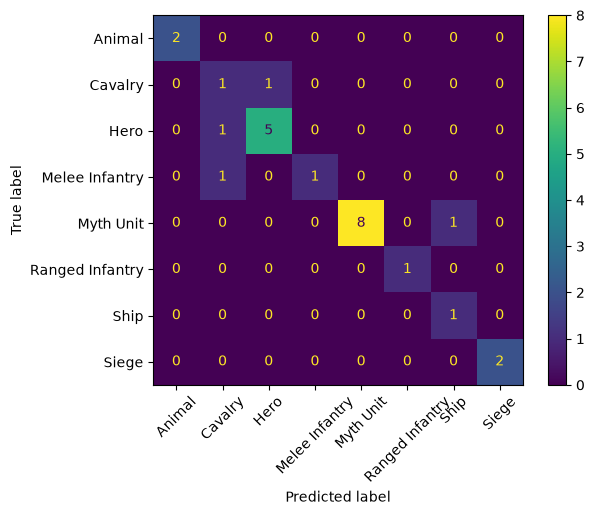

In [18]:
y_pred = arvore.predict(X_test)
print(pd.Series(resumo_metricas(y_test, y_pred)).round(3))
print("acurácia no treino:", round(accuracy_score(y_train, arvore.predict(X_train)), 3))
print(classification_report(y_test, y_pred, zero_division=0))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, xticks_rotation=45)
plt.show()

Validação cruzada da árvore base

In [19]:
pd.Series(avaliar_cv(DecisionTreeClassifier(criterion="entropy", random_state=42))).round(3)

acurácia            0.769
desvio acurácia     0.105
precisão (macro)    0.560
desvio precisão     0.169
dtype: float64

Poda da arvore \
Decidir o melhor alpha

In [20]:
caminho = DecisionTreeClassifier(criterion="entropy", random_state=42).cost_complexity_pruning_path(X, y)

linhas = []
#calular todos os alphas possíveis, e para cada alpha, calcular a acurácia e precisão
for alpha in np.unique(caminho.ccp_alphas):               # valores exatos, sem arredondar
    m = DecisionTreeClassifier(criterion="entropy", ccp_alpha=alpha, random_state=42)
    r = avaliar_cv(m)
    linhas.append({"alpha": alpha, "folhas": m.fit(X, y).get_n_leaves(), **r})

tab_poda = pd.DataFrame(linhas)
display(tab_poda[["alpha", "folhas", "acurácia", "precisão (macro)"]].round(4))

# melhor acurácia; no empate, a árvore com menos folhas
ALPHA = tab_poda.sort_values(["acurácia", "folhas"], ascending=[False, True]).iloc[0]["alpha"]
print("alpha escolhido:", ALPHA)


,alpha,folhas,acurácia,precisão (macro)
0,0.0000,18,0.7694,0.5599
1,0.0241,17,0.7694,0.5599
2,0.0332,15,0.7694,0.5599
3,0.0435,14,0.7806,0.5799
4,0.0470,13,0.7806,0.5882
5,0.0499,12,0.7931,0.6104
6,0.0626,11,0.7806,0.5879
7,0.0664,10,0.7458,0.5579
8,0.0831,9,0.7597,0.5657
9,0.1125,8,0.7097,0.4799


alpha escolhido: 0.04990011385634087


Testar a profundidade máxima da árvore 

,folhas máx (2^d),árvore acc,árvore prec,ada acc,ada prec
max_depth,,,,,
1,2,0.554,0.260,0.619,0.390
2,4,0.507,0.257,0.731,0.549
3,8,0.656,0.472,0.768,0.613
4,16,0.764,0.631,0.800,0.652
5,32,0.760,0.631,0.786,0.662
6,64,0.750,0.605,0.728,0.551
7,128,0.764,0.613,0.749,0.586
8,256,0.764,0.613,0.745,0.581


Árvore sem limite: {'acurácia': np.float64(0.764), 'desvio acurácia': np.float64(0.153), 'precisão (macro)': np.float64(0.613), 'desvio precisão': np.float64(0.221)}


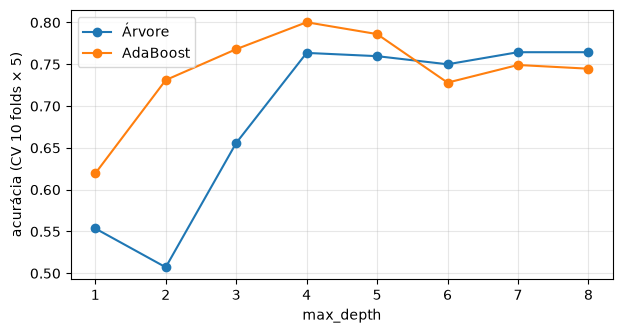

In [21]:
rkf = RepeatedKFold(n_splits=10, n_repeats=5, random_state=42)   # 10 folds repetidos 5 vezes

linhas = []
for d in range(1, 9):
    arv = DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=42)
    ada = AdaBoostClassifier(
        estimator=DecisionTreeClassifier(criterion="entropy", max_depth=d, random_state=42),
        n_estimators=50, random_state=42)
    ra, rb = avaliar_cv(arv, cv=rkf), avaliar_cv(ada, cv=rkf)
    linhas.append({"max_depth": d, "folhas máx (2^d)": 2 ** d,
                   "árvore acc": ra["acurácia"], "árvore prec": ra["precisão (macro)"],
                   "ada acc": rb["acurácia"], "ada prec": rb["precisão (macro)"]})

tab_prof = pd.DataFrame(linhas).set_index("max_depth")
display(tab_prof.round(3))

sem_limite = avaliar_cv(DecisionTreeClassifier(criterion="entropy", random_state=42), cv=rkf)
print("Árvore sem limite:", {k: round(v, 3) for k, v in sem_limite.items()})

plt.figure(figsize=(7, 3.5))
plt.plot(tab_prof.index, tab_prof["árvore acc"], marker="o", label="Árvore")
plt.plot(tab_prof.index, tab_prof["ada acc"], marker="o", label="AdaBoost")
plt.xlabel("max_depth"); plt.ylabel("acurácia (CV 10 folds × 5)"); plt.legend(); plt.grid(alpha=.3)
plt.show()

Arvore podada completa

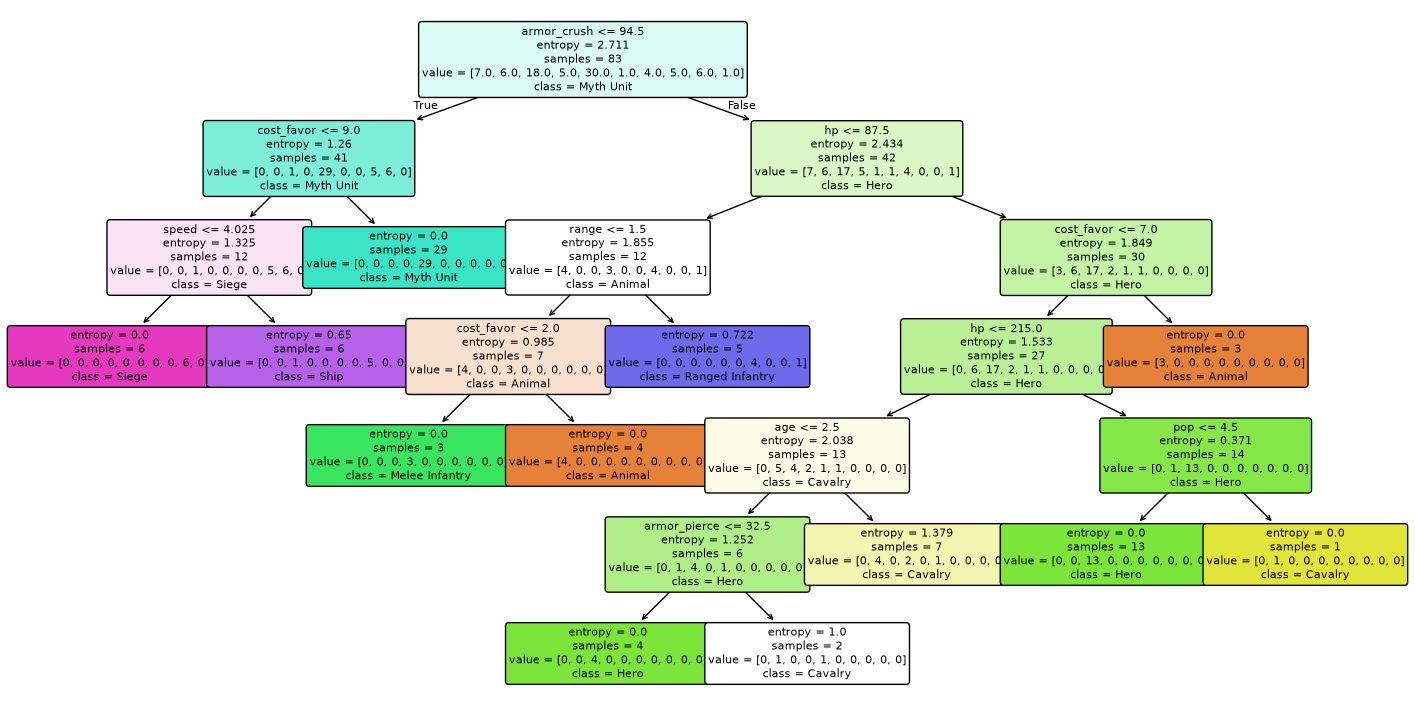

In [22]:
arvore_final = DecisionTreeClassifier(criterion="entropy", ccp_alpha=ALPHA, random_state=42).fit(X, y)
fig, ax = plt.subplots(figsize=(18, 9))
plot_tree(arvore_final, feature_names=ATRIBUTOS, class_names=list(arvore_final.classes_),
          filled=True, rounded=True, fontsize=8, ax=ax)

plt.show()

In [23]:
pd.Series(arvore_final.feature_importances_, index=ATRIBUTOS).sort_values(ascending=False).round(3)

armor_crush     0.345
cost_favor      0.276
hp              0.166
speed           0.058
range           0.057
age             0.045
armor_pierce    0.027
pop             0.025
dmg_hack        0.000
dmg_pierce      0.000
dmg_crush       0.000
armor_hack      0.000
train_time      0.000
does_attack     0.000
dtype: float64

Testar classificador com boosting

In [24]:
from sklearn.ensemble import AdaBoostClassifier

candidatos = {
    "Árvore (entropia, sem poda)": DecisionTreeClassifier(criterion="entropy", random_state=42),
    "Árvore podada": DecisionTreeClassifier(criterion="entropy", ccp_alpha=ALPHA, random_state=42),
    "AdaBoost + Stump (profundidade 1)": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(max_depth=1), n_estimators=50, random_state=42),
    "AdaBoost + árvores (profundidade 4)": AdaBoostClassifier(
        estimator=DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=42),
        n_estimators=50, random_state=42),
}

tabela = pd.DataFrame({nome: avaliar_cv(m) for nome, m in candidatos.items()}).T

# escolha: maior acurácia; se empatar, maior precisão macro
ordem = tabela.round(4).sort_values(["acurácia", "precisão (macro)"], ascending=False)
display(ordem)

nome_final = ordem.index[0]
print("Modelo escolhido:", nome_final)

,acurácia,desvio acurácia,precisão (macro),desvio precisão
AdaBoost + árvores (profundidade 4),0.7944,0.1254,0.6329,0.1703
Árvore podada,0.7931,0.1112,0.6104,0.1777
"Árvore (entropia, sem poda)",0.7694,0.1053,0.5599,0.1686
AdaBoost + Stump (profundidade 1),0.6347,0.1944,0.3740,0.2499


Modelo escolhido: AdaBoost + árvores (profundidade 4)


Matriz de confusão dos modelos

Árvore (entropia, sem poda): acurácia = 0.771
Árvore podada: acurácia = 0.795
AdaBoost + Stump (profundidade 1): acurácia = 0.639
AdaBoost + árvores (profundidade 4): acurácia = 0.795


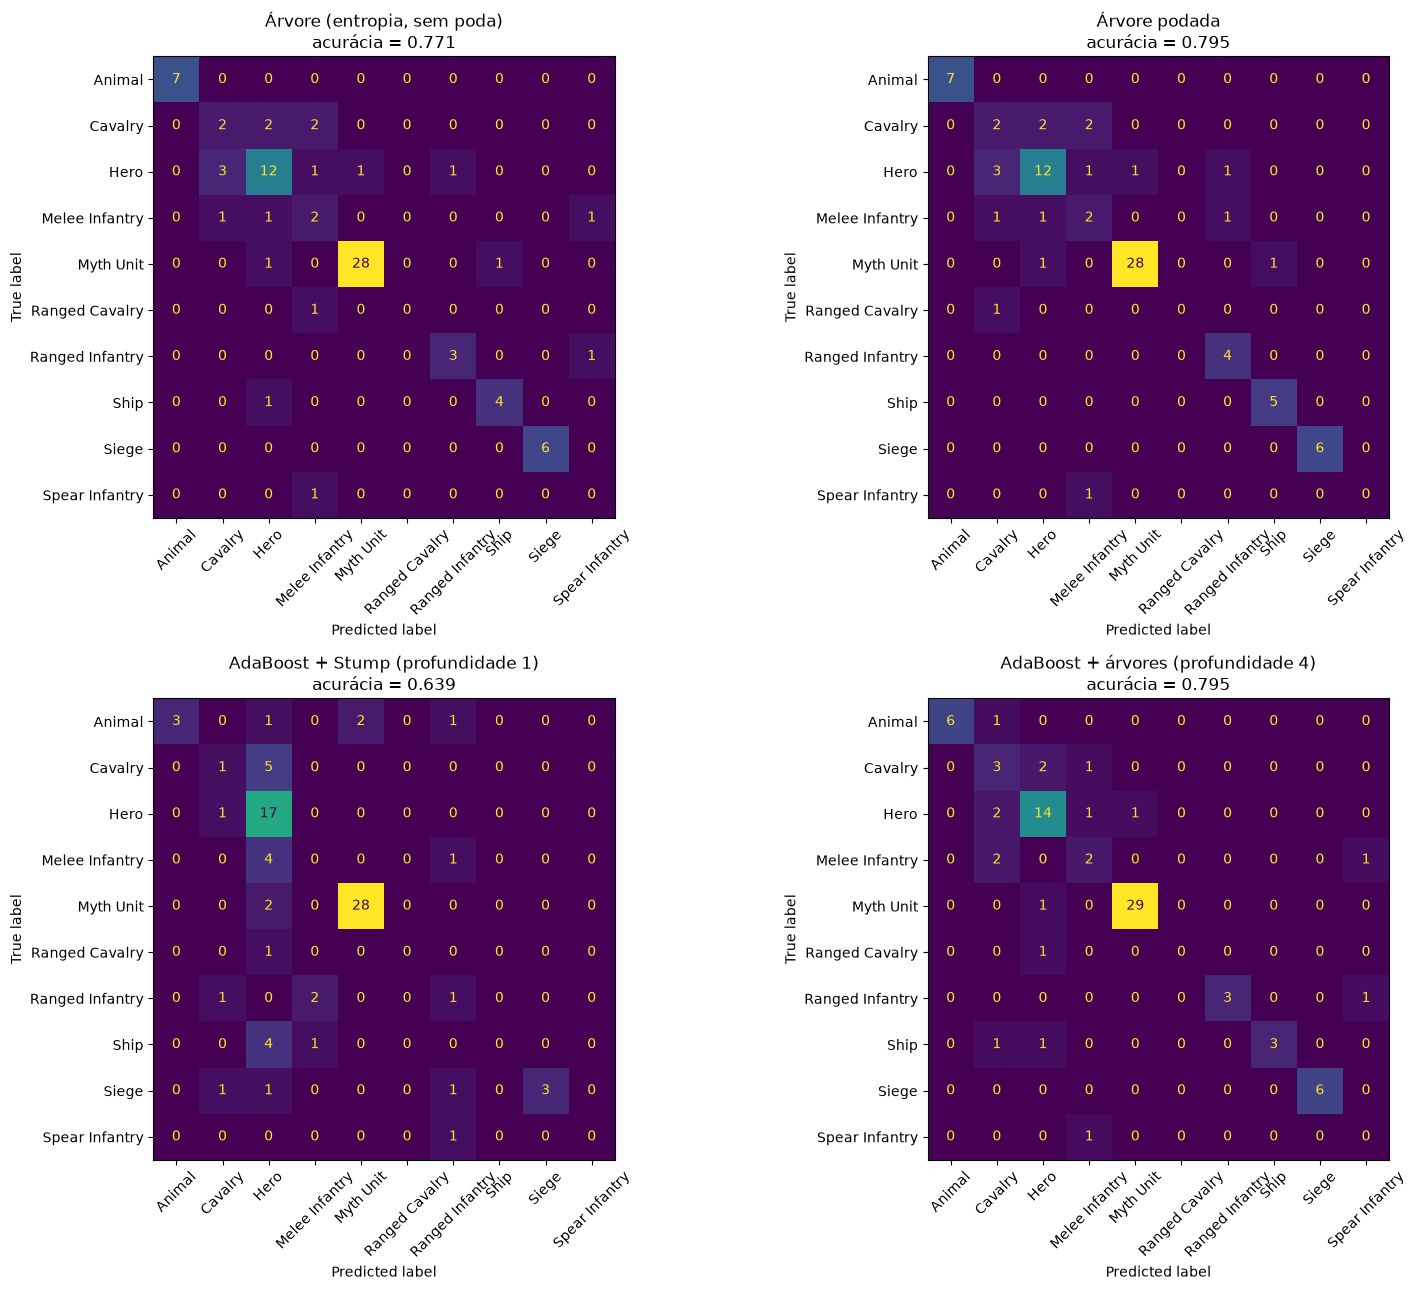

                 precision    recall  f1-score   support

         Animal       1.00      0.86      0.92         7
        Cavalry       0.33      0.50      0.40         6
           Hero       0.74      0.78      0.76        18
 Melee Infantry       0.40      0.40      0.40         5
      Myth Unit       0.97      0.97      0.97        30
 Ranged Cavalry       0.00      0.00      0.00         1
Ranged Infantry       1.00      0.75      0.86         4
           Ship       1.00      0.60      0.75         5
          Siege       1.00      1.00      1.00         6
 Spear Infantry       0.00      0.00      0.00         1

       accuracy                           0.80        83
      macro avg       0.64      0.59      0.61        83
   weighted avg       0.82      0.80      0.80        83



In [25]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.metrics import accuracy_score

classes = sorted(y.unique())
preds_cv = {nome: cross_val_predict(m, X, y, cv=kf) for nome, m in candidatos.items()}   # só para a matriz

fig, axes = plt.subplots(2, 2, figsize=(16, 13))
for ax, (nome, p) in zip(axes.ravel(), preds_cv.items()):
    ConfusionMatrixDisplay.from_predictions(y, p, labels=classes, xticks_rotation=45, ax=ax, colorbar=False)
    print(f"{nome}: acurácia = {accuracy_score(y, p):.3f}")
    ax.set_title(f"{nome}\nacurácia = {accuracy_score(y, p):.3f}")
plt.tight_layout(); plt.show()

print(classification_report(y, preds_cv[nome_final], zero_division=0))   #precisão e recall por classe

Testar a eficácia da coluna does attack

In [26]:
for nome in candidatos:
    sem = avaliar_cv(candidatos[nome], dados=X.drop(columns="does_attack"))
    print(f"{nome:32s} sem={sem['acurácia']:.3f}  com={tabela.loc[nome, 'acurácia']:.3f}")

Árvore (entropia, sem poda)      sem=0.733  com=0.769
Árvore podada                    sem=0.756  com=0.793
AdaBoost + Stump (profundidade 1) sem=0.635  com=0.635
AdaBoost + árvores (profundidade 4) sem=0.807  com=0.794


In [27]:
def holdout_repetido(fabrica, tamanho_teste, raras_no_treino, n_sorteios=30):
    raras = y.map(y.value_counts()) < 2
    linhas = []
    for semente in range(n_sorteios):
        if raras_no_treino:
            X_tr, X_te, y_tr, y_te = train_test_split(
                X[~raras], y[~raras], test_size=tamanho_teste,
                random_state=semente, stratify=y[~raras])
            X_tr = pd.concat([X_tr, X[raras]]); y_tr = pd.concat([y_tr, y[raras]])
        else:
            X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=tamanho_teste, random_state=semente)
        p = fabrica().fit(X_tr, y_tr).predict(X_te)
        linhas.append(resumo_metricas(y_te, p))
    r = pd.DataFrame(linhas)
    return {"unid. teste": len(y_te), "acurácia média": r["acurácia"].mean(), "desvio": r["acurácia"].std(),
            "mín": r["acurácia"].min(), "máx": r["acurácia"].max(), "precisão macro": r["precisão (macro)"].mean()}

fabricas = {
    "Árvore": lambda: DecisionTreeClassifier(criterion="entropy", random_state=42),
    "AdaBoost (prof. 4)": lambda: AdaBoostClassifier(
        estimator=DecisionTreeClassifier(criterion="entropy", max_depth=4, random_state=42),
        n_estimators=50, random_state=42),
}

linhas = []
for raras_no_treino in [False, True]:
    for tam in [0.2, 0.3, 0.4]:
        for nome, fab in fabricas.items():
            linhas.append({"raras no treino": raras_no_treino, "teste": tam, "modelo": nome,
                           **holdout_repetido(fab, tam, raras_no_treino)})
pd.DataFrame(linhas).round(3)

,raras no treino,teste,modelo,unid. teste,acurácia média,desvio,mín,máx,precisão macro
0,False,0.2,Árvore,17,0.714,0.108,0.412,0.882,0.574
1,False,0.2,AdaBoost (prof. 4),17,0.778,0.074,0.588,0.941,0.668
2,False,0.3,Árvore,25,0.716,0.087,0.520,0.920,0.562
3,False,0.3,AdaBoost (prof. 4),25,0.769,0.081,0.640,0.920,0.637
4,False,0.4,Árvore,34,0.706,0.077,0.559,0.853,0.544
5,False,0.4,AdaBoost (prof. 4),34,0.772,0.074,0.647,0.941,0.626
6,True,0.2,Árvore,17,0.775,0.098,0.529,0.882,0.659
7,True,0.2,AdaBoost (prof. 4),17,0.837,0.077,0.647,0.941,0.727
8,True,0.3,Árvore,25,0.755,0.076,0.600,0.920,0.653
9,True,0.3,AdaBoost (prof. 4),25,0.824,0.074,0.680,0.960,0.729


Treinar o melhor modelo e gerar as previsões

In [28]:
print("Modelo escolhido:", nome_final)

modelo_final = candidatos[nome_final].fit(X, y)          # treina com os 83 registros

previsoes = teste[ATRIBUTOS].copy()
previsoes["classe_prevista"] = modelo_final.predict(teste[ATRIBUTOS])
previsoes.index.name = "unidade_teste"
#previsoes.to_csv("previsoes_AgeOfMythology.csv")

# previsão dos outros modelos, para ver onde discordam
alternativas = pd.DataFrame({n: m.fit(X, y).predict(teste[ATRIBUTOS])
                             for n, m in candidatos.items() if "Stump" not in n})
alternativas.index.name = "unidade_teste"
alternativas["todos concordam"] = alternativas.nunique(axis=1) == 1

display(previsoes)
display(alternativas)

Modelo escolhido: AdaBoost + árvores (profundidade 4)


,age,pop,dmg_hack,dmg_pierce,dmg_crush,range,hp,armor_hack,armor_pierce,armor_crush,speed,train_time,cost_favor,does_attack,classe_prevista
unidade_teste,,,,,,,,,,,,,,,
0,3.0,5.0,12.0,0.0,0.0,1.0,800.0,60.0,60.0,80.0,3.60,19.0,15.0,1,Myth Unit
1,2.0,1.0,5.0,0.0,0.0,1.0,50.0,10.0,5.0,99.0,3.00,20.0,5.0,1,Animal
2,2.0,3.0,11.0,5.0,0.0,1.0,400.0,30.0,50.0,99.0,3.80,17.0,5.0,1,Hero
3,3.0,2.0,0.0,6.0,0.0,20.0,60.0,15.0,15.0,99.0,3.75,12.0,0.0,1,Ranged Infantry
4,3.0,3.0,8.0,0.0,0.0,1.0,120.0,10.0,35.0,99.0,4.00,15.0,0.0,1,Cavalry
5,3.0,2.0,8.0,4.0,0.0,1.0,95.0,15.0,10.0,99.0,3.50,14.0,0.0,1,Melee Infantry
6,4.0,3.0,10.0,0.0,30.0,16.0,180.0,30.0,70.0,50.0,2.50,21.0,0.0,1,Siege
7,4.0,3.0,11.0,10.0,0.0,1.0,140.0,15.0,40.0,99.0,3.50,22.0,0.0,1,Cavalry
8,2.0,3.0,10.0,0.0,8.0,1.0,175.0,50.0,25.0,80.0,4.00,26.0,10.0,1,Myth Unit


,"Árvore (entropia, sem poda)",Árvore podada,AdaBoost + árvores (profundidade 4),todos concordam
unidade_teste,,,,
0,Myth Unit,Myth Unit,Myth Unit,True
1,Animal,Animal,Animal,True
2,Hero,Hero,Hero,True
3,Ranged Infantry,Ranged Infantry,Ranged Infantry,True
4,Cavalry,Cavalry,Cavalry,True
5,Ranged Cavalry,Cavalry,Melee Infantry,False
6,Siege,Siege,Siege,True
7,Cavalry,Cavalry,Cavalry,True
8,Myth Unit,Myth Unit,Myth Unit,True
